<div style="background-color: #f5f5f5; padding: 20px; border-radius: 10px; border: 1px solid #e0e0e0;">
<table style="width:100%; border:none;">
  <tbody><tr style="border:none;">
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
    <td style="width:60%; text-align:center; border:none; vertical-align:middle;">
      <h1 style="margin:0; color:#333;">University of Isfahan</h1>
      <h2 style="margin:0; color:#555; font-weight:normal;">Faculty of Mathematics and Statistics</h2>
      <br/>
      <hr style="border: 1px solid #ccc; margin-top:15px; margin-bottom:15px;">
      <h3 style="margin:0; color:#0056b3;">Fourth Practical Homework: Support Vector Machines</h3>
      <br/>
      <h4 style="margin:0; font-size: 1.1em; color: #333; line-height: 1.6; margin-top: 15px; display: inline-block;">
        <strong>Course:</strong> Machine Learning<br>
        <strong>Instructor:</strong> Dr. Mohsen Alambardar<br>
        <strong>Semester:</strong> Fall 1404-1405
      </h4>
    </td>
    <td style="width:20%; text-align:center; border:none; vertical-align:middle;">
      <img src="https://i.ibb.co/pjbk15cs/UI-Logo.png" alt="UI Logo" width="100">
    </td>
  </tr>
</tbody></table>
</div>

<div style="background-color: #f5f5f5; border: 1px solid #f5f5f5; padding: 20px; border-radius: 10px; margin-top: 25px; margin-bottom: 25px;">
  
  <h3 style="text-align: center; margin-top: 0; color: #0056b3;">Student Information</h3>
  <p style="text-align: center; color: #555; margin-bottom: 20px; margin-top: 0;">
    Please fill in your details below.
  </p>

  <table style="width: 60%; margin-left: auto; margin-right: auto; border: none; font-size: 1.1em; color: #333;">
    <tbody>
      <tr>
        <td style="text-align: right; padding: 8px; width: 35%;"><strong>Student Name:</strong></td>
        <td style="text-align: left; padding: 8px;"><em>Hosna Soltanolkottabi</em></td>
      </tr>
      <tr>
        <td style="text-align: right; padding: 8px;"><strong>Student ID:</strong></td>
        <td style="text-align: left; padding: 8px;"><em></em></td>  
      </tr>
    </tbody>
  </table>
  
</div>

# **HW4-P: Digits Classification with Support Vector Machines**

In the workshop, you used synthetic "blobs" to understand the basics of SVM. Now, we will apply Support Vector Machines to a **real-world problem**: Handwritten Digit Recognition.

We will use the `sklearn.datasets.load_digits` dataset (a smaller, 8x8 pixel version of MNIST). This allows us to visualize what the SVM actually "sees" and interpret its decisions in a meaningful way.

**Our Goals:**
1. **Handle Real Data:** Load, filter, and split the digits dataset.
2. **Linear SVM (Interpretable AI):** Train a linear model and visualize the learned weights to understand how the machine distinguishes a '0' from a '1'.
3. **RBF SVM & Tuning:** Train a non-linear model using the Radial Basis Function (RBF) kernel and perform a **Grid Search** to find the optimal hyperparameters ($C$ and $\gamma$).
4. **Visualizing Support Vectors:** Identify and plot the specific images that define the decision boundary (the support vectors), connecting back to the concept of the Margin.

---

## **1. Setup: Importing Libraries**

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import seaborn as sns

# Set default figure size and style
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.style.use('ggplot')

---

## **2. Data Preparation**

We will use the **Digits dataset**. It contains 1797 images of 8x8 pixels, representing digits from 0 to 9.

**Your Task:**
1. Load the dataset.
2. Filter it to contain **only** the digits **'0'** and **'1'** (Binary Classification).
3. Split the data into training (80%) and testing (20%) sets.

### 2.1. **Complete the Code `#TODO`**

Original dataset shape: (1797, 64)
Filtered binary dataset shape: (360, 64)
Training set shape: (288, 64)
Testing set shape: (72, 64)



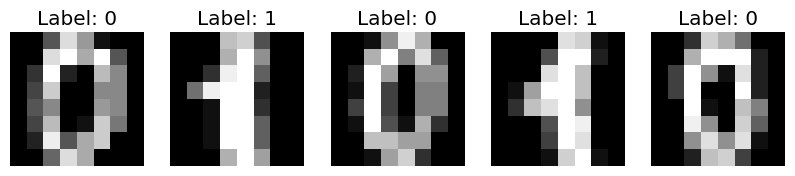

In [3]:
# Load the digits dataset
digits = datasets.load_digits()
X, y = digits.data, digits.target

# TODO: Filter the dataset to keep only classes 0 and 1
# Hint: Create a mask boolean array where y == 0 or y == 1
mask = (y <= 1)
X_binary = X[mask]
y_binary = y[mask]

# TODO: Split the data into training and testing sets (80% train, 20% test)
# Use random_state=42 for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X_binary, y_binary, test_size=0.2, random_state=42)

print(f"Original dataset shape: {X.shape}")
# Note: The following prints will fail until you define the variables above
print(f"Filtered binary dataset shape: {X_binary.shape}")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}\n")

# Let's visualize a few examples
plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_binary[i].reshape(8, 8), cmap='gray')
    plt.title(f"Label: {y_binary[i]}")
    plt.axis('off')
plt.show()

---

## **3. Part A: The Linear View (Interpretable AI)**

Linear SVMs are powerful because they are **interpretable**. The model learns a weight vector $\mathbf{w}$ and a bias $b$. The decision function is $f(x) = \mathbf{w}^T \mathbf{x} + b$.

Since our input images are 8x8 pixels flattened into a 64-dimensional vector, the learned weight vector $\mathbf{w}$ will also have 64 dimensions. By reshaping this weight vector back into an 8x8 grid, we can visualize exactly which pixels the SVM uses to distinguish a '0' from a '1'.

In this section, you will define a class `LinearSVMAnalysis` to encapsulate the model training and visualization logic.

### 3.1. **Complete the Code `#TODO`**

Linear SVM Test Accuracy: 1.0



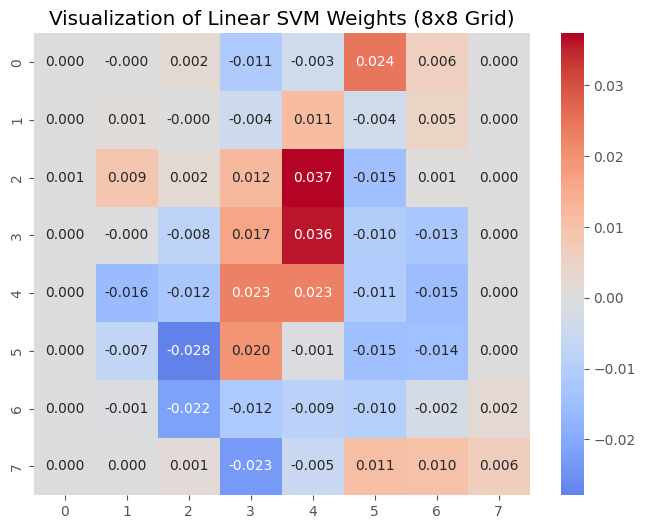

In [4]:
class LinearSVMAnalysis:
    def __init__(self):
        # TODO: Initialize the SVC model with a linear kernel
        self.model = SVC(kernel='linear')

    def train(self, X_train, y_train):
        # TODO: Fit the model to the training data
        self.model.fit(X_train, y_train)

    def evaluate(self, X_test, y_test):
        # TODO: Predict on the test set and return accuracy
        y_pred = self.model.predict(X_test)
        return accuracy_score(y_test, y_pred)

    def plot_weights(self):
        # TODO: Retrieve the coefficients (weights) from the trained model
        # Hint: Look for the .coef_ attribute of the SVC model
        weights = self.model.coef_

        # TODO: Reshape the weights into an 8x8 grid
        # The shape of weights is typically (1, 64)
        weight_grid = weights.reshape(8, 8)

        # Plotting the heatmap
        plt.figure(figsize=(8, 6))
        sns.heatmap(weight_grid, annot=True, fmt=".3f", cmap='coolwarm', center=0)
        plt.title("Visualization of Linear SVM Weights (8x8 Grid)")
        plt.show()

# --- Execution ---
linear_svm = LinearSVMAnalysis()
linear_svm.train(X_train, y_train)
acc = linear_svm.evaluate(X_test, y_test)
print(f"Linear SVM Test Accuracy: {acc}\n")
linear_svm.plot_weights()

### 3.2. **Analysis 1: Interpreting the Weights** `#TODO`

**Question:** Look at the heatmap above. Which pixels correspond to high **positive** weights (red) and which correspond to high **negative** weights (blue)? Explain how this relates to the geometric shape of a '0' versus a '1'.

**Your Answer:**
<p dir='rtl'>
برای داده های مربوط به کلاس یک جوهر به صورت استوانه و در مرکز تصویر قرار دارد اما در کلاس صفر جوهر به صورت بیضی حول مرکز تصویر پخش شده است.
بنابراین همان طور که در شکل نیز مشاهده میشود در مرکز تصویر پیکسل ها مقدار مثبت(قرمز) دارند و در اطراف آن پیکسل ها مقدار منفی(آبی) دارند توجه داشته باشید همانطور که مشخص است پیکسل هایی که در آن ها کلاس یک و صفر هر دو جوهر داشتند با توجه به این که وزن کدام کلاس بیشتر بوده مقدار داخل پیکسل تعدیل شده و چه بسا صفر میشوند. 
</p>

---

## **4. Part B: The RBF Kernel & Hyperparameter Tuning**

Real-world data is rarely perfectly linear. The **RBF (Radial Basis Function)** kernel allows us to draw non-linear boundaries by measuring similarity between points.

The RBF kernel has two crucial hyperparameters:
* **$C$**: Controls the trade-off between a smooth decision boundary and classifying training points correctly (Regularization).
  - Low $C$ = smoother boundary
  - High $C$ = strictly correct classification
* **$\gamma$ (gamma)**: Defines how far the influence of a single training example reaches.
  - Low $\gamma$ = far reach (smooth)
  - High $\gamma$ = close reach (complex/islands)


### 4.1. **Tutorial: Grid Search and Cross-Validation**

In the lectures, we discussed **Cross-Validation** (CV) as the correct way to tune these parameters. Instead of manually writing loops to check every combination of $C$ and $\gamma$ and manually splitting the data 5 times, `scikit-learn` provides a powerful tool called `GridSearchCV` that automates this.

**How `GridSearchCV` works:**
1. You define a dictionary of parameters you want to test (e.g., different values for $C$ and $\gamma$).
2. It automatically creates a "grid" of all possible combinations.
3. For *each* combination, it runs **K-Fold Cross Validation** (splitting data into K parts, training on K-1, validating on 1).
4. It returns the combination that had the highest average validation accuracy.

**Syntax Example:**
```python
# 1. Define the model
svc = SVC()

# 2. Define the grid
param_grid = {'C': [0.1, 1], 'gamma': [0.01, 0.1]}

# 3. Create the GridSearch Object
grid = GridSearchCV(estimator=svc, param_grid=param_grid, cv=5, scoring='accuracy')

# 4. Fit it (Just like a normal model!)
grid.fit(X_train, y_train)

# 5. Get results
best_parameters = grid.best_params_
best_model = grid.best_estimator_
```

Now, you will implement this in the class below.

### 4.2. **Complete the Code `#TODO`**

Best Parameters found: {'C': 0.1, 'gamma': 0.001}



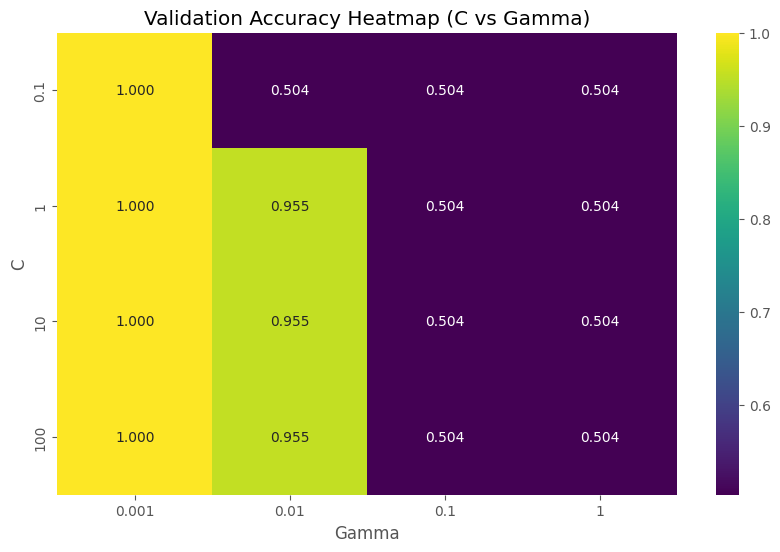

In [5]:
class RBFSVMTuner:
    def __init__(self):
        # TODO: Define the parameter grid
        # Search range for C: [0.1, 1, 10, 100]
        # Search range for gamma: [0.001, 0.01, 0.1, 1]
        # Don't forget to specify the 'kernel' as 'rbf'
        self.param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1]}
        self.best_model = None
        self.grid_search = None

    def tune(self, X_train, y_train):
        # TODO: Initialize GridSearchCV with SVC(), your param_grid, cv=5, and scoring='accuracy'
        # Refer to the tutorial text above if you need help with syntax
        self.grid_search = GridSearchCV(estimator=SVC(kernel='rbf'), param_grid=self.param_grid, cv=5, scoring='accuracy')

        # TODO: Fit the grid search to the data
        self.grid_search.fit(X_train, y_train)

        # Save the best estimator
        if self.grid_search:
            self.best_model = self.grid_search.best_estimator_
            print(f"Best Parameters found: {self.grid_search.best_params_}\n")

    def plot_results(self):
        if self.grid_search is None:
            print("Error: You must implement tune() before plotting results.")
            return

        # Extract results for plotting
        results = self.grid_search.cv_results_
        scores = results['mean_test_score'].reshape(len(self.param_grid['C']), len(self.param_grid['gamma']))

        plt.figure(figsize=(10, 6))
        sns.heatmap(scores, annot=True, fmt=".3f", cmap='viridis',
                    xticklabels=self.param_grid['gamma'],
                    yticklabels=self.param_grid['C'])
        plt.xlabel('Gamma')
        plt.ylabel('C')
        plt.title('Validation Accuracy Heatmap (C vs Gamma)')
        plt.show()

# --- Execution ---
rbf_tuner = RBFSVMTuner()
rbf_tuner.tune(X_train, y_train)
rbf_tuner.plot_results()

### 4.3. **Analysis 2: Hyperparameter Sensitivity** `#TODO`

**Question:** Referencing the heatmap above, explain the effect you observe. Specifically, what happens to the validation accuracy when $\gamma$ is very high (e.g., 1.0)? Does this indicate **overfitting** or **underfitting**?

**Your Answer:**
<p dir='rtl'>
همانطور که در شکل مشخص است هنگامی که مقدار گاما افزایش پیدا میکند accuracy کاهش پیدا میکند و یعنی خطای برای داده های آموزشی کم است ولی برای داده جدید زیاد است پس overfit رخ میدهد
در واقع هر بردار پشتیبان یک شعاع اطراف خودش دارد هنگامی که این شعاع کوچک است مرز تصمیم پیچیده میشود و هنگامی که این شعاع بزرگ تر است از پیچیدگی مرز تصمیم کاسته میشود.
</p>

---

## **5. Part C: Visualizing Support Vectors**

The core idea of SVM is the **Margin**. The boundary is defined **only** by the data points that lie closest to it (or within the margin). These points are called **Support Vectors**.

In this final section, we will extract these support vectors from your best RBF model and visualize them. This helps us verify if the "hard" cases are indeed the ambiguous or messy digits.

### 5.1. **Complete the Code `#TODO`**

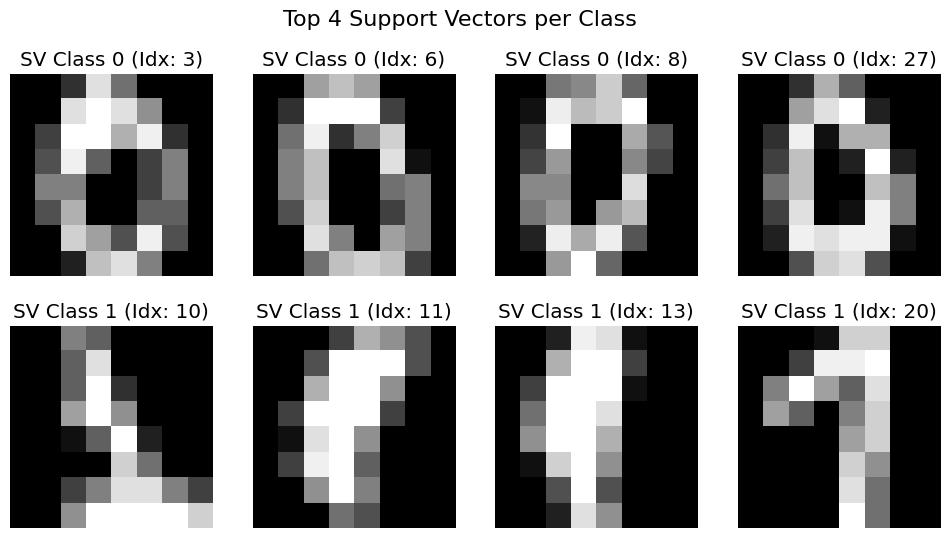

In [6]:
def visualize_support_vectors(model, X_train, y_train):
    # TODO: Get the indices of the support vectors
    # Hint: The attribute is .support_
    sv_indices = model.support_

    # TODO: Get the support vectors and their labels
    # Hint: Use model.support_vectors_ and index y_train using sv_indices
    support_vectors = model.support_vectors_
    support_vector_labels = y_train[sv_indices]

    # Separate indices for class 0 and class 1
    # We want to find the first 4 support vectors for each class for visualization
    # Hint: Filter sv_indices where support_vector_labels is 0 (or 1)
    sv_indices_class_0 = sv_indices[support_vector_labels == 0][:4]
    sv_indices_class_1 = sv_indices[support_vector_labels == 1][:4]

    # Plotting
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    fig.suptitle('Top 4 Support Vectors per Class', fontsize=16)

    # Plot Class 0 Support Vectors
    # Note: We provided the plotting loop, you just need to ensure indices are correct above
    if sv_indices_class_0 is not None:
        for i, idx in enumerate(sv_indices_class_0):
            img = X_train[idx].reshape(8, 8)
            axes[0, i].imshow(img, cmap='gray')
            axes[0, i].set_title(f"SV Class 0 (Idx: {idx})")
            axes[0, i].axis('off')

    # Plot Class 1 Support Vectors
    if sv_indices_class_1 is not None:
        for i, idx in enumerate(sv_indices_class_1):
            img = X_train[idx].reshape(8, 8)
            axes[1, i].imshow(img, cmap='gray')
            axes[1, i].set_title(f"SV Class 1 (Idx: {idx})")
            axes[1, i].axis('off')

    plt.show()

# --- Execution ---
# We use the best model found by our tuner
visualize_support_vectors(rbf_tuner.best_model, X_train, y_train)

### 5.2. **Analysis 3: The Hard Cases** `#TODO`

**Question:** Look at the images of the support vectors above. Do these digits look like "perfect" examples of 0s and 1s, or do they look "messy" or ambiguous? Explain why the SVM chooses these specific points to define the boundary, referencing the concept of the **Margin**.

**Your Answer:**
<p dir='rtl'>
بردارهای پشتیبان داده هایی هستند که شکل بهم ریخته دارند چرا که این داده ها نزدیکترین ها به مرز تصمیم هستند علاوه بر این کلاس بندی این داده ها سخت تر است  پس این ها مهمترین ها در تعیین مرز هستند.
</p>

<div style="background-color: #e6f7ff; padding: 20px; border-radius: 10px; border: 1px solid #b3e0ff; text-align: center;">
  <h3 style="margin:0; color:#0056b3;">Congratulations!</h3>
  <p style="color:#333; font-size: 1.1em;">You have completed the fourth practical homework.</p>
</div>